# Flow-A11y Publication Analysis

This notebook reproduces the paper-facing v4 analysis from the bundled normalized tables. It combines effectiveness, baseline comparison, criterion-family behavior, error audits, evidence validity, coverage, and cost. No browser, website access, or Gemini API key is required.

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

APP_ROOT = next(
    (candidate for candidate in (Path.cwd(), *Path.cwd().parents)
     if (candidate / "benchmarking" / "dynamic").is_dir()),
    None,
)
if APP_ROOT is None:
    raise RuntimeError("Could not locate the a11y-agent artifact root.")
if str(APP_ROOT) not in sys.path:
    sys.path.insert(0, str(APP_ROOT))
from benchmarking.dynamic.notebook_support import load_dynamic_tables, read_benchmark_summary, resolve_dynamic_results_dir

RESULTS_DIR = resolve_dynamic_results_dir(APP_ROOT)
tables = load_dynamic_tables(RESULTS_DIR)
summary = read_benchmark_summary(RESULTS_DIR)
sns.set_theme(style="whitegrid", context="notebook")

overview = pd.DataFrame([{
    "attempted_scenarios": summary.get("scenarios"),
    "completed_scenarios": summary.get("task_success", {}).get("task_success_count"),
    "attempted_rows": summary.get("attempted_rows"),
    "scored_rows": summary.get("scored_rows"),
    "supported_criteria": 45,
    "judge": summary.get("dynamic_judge"),
}])
display(overview)

,attempted_scenarios,completed_scenarios,attempted_rows,scored_rows,supported_criteria,judge
0,19,17,855,765,45,gemini


## RQ1: Effectiveness on Real Interaction Flows

Primary metrics use the 765 rows from the 17 scenarios that passed the scoring gate. Attempted tables retain all 855 oracle rows for coverage auditing.

,metric,numerator,denominator,value_percent,ci_95_percent
0,Exact five-way accuracy,349.0,765.0,45.6,"[43.0, 48.2]"
1,Fail precision,12.0,29.0,41.4,"[17.5, 64.7]"
2,Fail recall,12.0,31.0,38.7,"[13.8, 68.2]"
3,Fail F1,NaN,NaN,40.0,"[16.0, 60.0]"
4,Pass precision,83.0,105.0,79.0,"[68.6, 88.7]"
5,Pass recall,83.0,182.0,45.6,"[37.2, 54.2]"


actual_status,fail,incomplete,not_applicable,pass,warning
expected_status,,,,,
fail,12,6,0,7,6
not_applicable,3,237,252,13,12
pass,12,37,35,83,15
warning,2,24,5,2,2


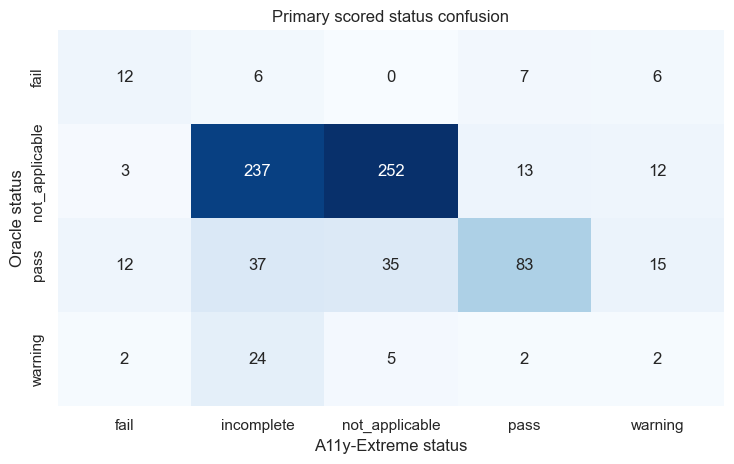

In [2]:
metric_names = {
    "exact_status_accuracy": "Exact five-way accuracy",
    "fail_precision_micro": "Fail precision",
    "fail_recall_micro": "Fail recall",
    "fail_f1_micro": "Fail F1",
    "pass_precision_micro": "Pass precision",
    "pass_recall_micro": "Pass recall",
}
quality = tables["quality_summary"].copy()
headline = quality[quality["metric"].isin(metric_names)].copy()
headline["metric"] = headline["metric"].map(metric_names)
headline["value_percent"] = (pd.to_numeric(headline["value"], errors="coerce") * 100).round(1)
headline["ci_95_percent"] = headline.apply(
    lambda r: f"[{100*float(r['ci_low']):.1f}, {100*float(r['ci_high']):.1f}]"
    if pd.notna(r.get("ci_low")) and pd.notna(r.get("ci_high")) else "", axis=1)
display(headline[["metric", "numerator", "denominator", "value_percent", "ci_95_percent"]].reset_index(drop=True))

confusion = tables["status_confusion"].copy()
confusion["count"] = pd.to_numeric(confusion["count"], errors="coerce").fillna(0).astype(int)
confusion_matrix = confusion.pivot(index="expected_status", columns="actual_status", values="count").fillna(0).astype(int)
display(confusion_matrix)
fig, ax = plt.subplots(figsize=(7.5, 4.8))
sns.heatmap(confusion_matrix, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
ax.set(title="Primary scored status confusion", xlabel="Flow-A11y status", ylabel="Oracle status")
plt.tight_layout(); plt.show()

## RQ2: Benefit over a Generic Browser-Agent Audit

Both systems are compared on the same scored oracle rows.

,baseline_id,oracle_rows,exact_matches,incomplete_rows,predicted_fails,exact_accuracy_percent,incomplete_percent
0,gemini-dynamic-wcag,765,349,304,29,45.6,39.7
1,naive-browser-use-global-audit,765,25,723,3,3.3,94.5


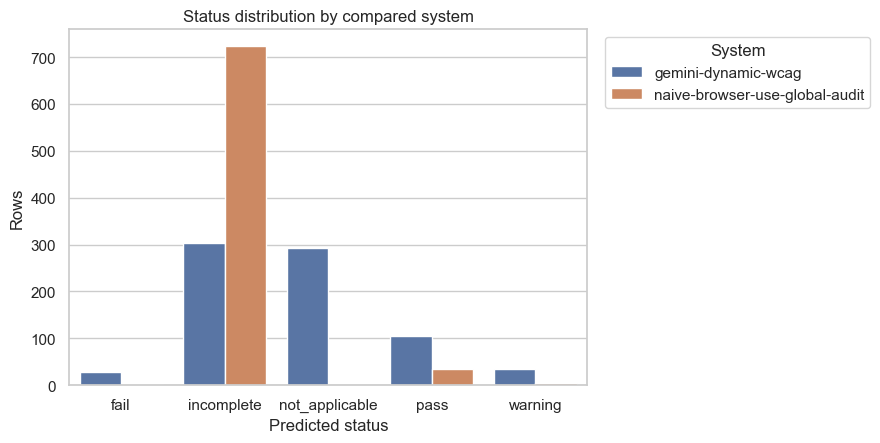

In [3]:
comparison = tables["baseline_comparison"].copy()
comparison["matched_bool"] = comparison["matched"].astype(str).str.lower().eq("true")
scoreboard = comparison.groupby("baseline_id").agg(
    oracle_rows=("criterion_id", "size"),
    exact_matches=("matched_bool", "sum"),
    incomplete_rows=("actual_status", lambda x: (x == "incomplete").sum()),
    predicted_fails=("actual_status", lambda x: (x == "fail").sum()),
).reset_index()
scoreboard["exact_accuracy_percent"] = (100*scoreboard["exact_matches"]/scoreboard["oracle_rows"]).round(1)
scoreboard["incomplete_percent"] = (100*scoreboard["incomplete_rows"]/scoreboard["oracle_rows"]).round(1)
display(scoreboard)
status_counts = comparison.groupby(["baseline_id", "actual_status"]).size().rename("count").reset_index()
fig, ax = plt.subplots(figsize=(9, 4.6))
sns.barplot(data=status_counts, x="actual_status", y="count", hue="baseline_id", ax=ax)
ax.set(title="Status distribution by compared system", xlabel="Predicted status", ylabel="Rows")
ax.legend(title="System", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()

## RQ3: Criterion-Family Capability and Failure Profile

Family results are descriptive because several families contain few oracle failures.

In [4]:
findings = tables["finding_status_records"].copy()
scored = findings[findings["scored"].astype(str).str.lower().eq("true")].copy()
scored["matched_bool"] = scored["matched_expected"].astype(str).str.lower().eq("true")
scored["packet_criterion_family"] = scored["packet_criterion_family"].replace("", np.nan).fillna("other")
family = scored.groupby("packet_criterion_family").agg(
    rows=("criterion_id", "size"), exact_matches=("matched_bool", "sum"),
    oracle_fails=("expected_status", lambda x: (x == "fail").sum()),
    predicted_fails=("status", lambda x: (x == "fail").sum()),
    incomplete_rows=("status", lambda x: (x == "incomplete").sum()),
).reset_index()
family["exact_accuracy_percent"] = (100*family["exact_matches"]/family["rows"]).round(1)
display(family.sort_values("exact_accuracy_percent", ascending=False).reset_index(drop=True))
criterion = scored.groupby(["criterion_id", "criterion_name"]).agg(rows=("scenario_id", "size"), exact_matches=("matched_bool", "sum")).reset_index()
criterion["exact_accuracy_percent"] = (100*criterion["exact_matches"]/criterion["rows"]).round(1)
display(criterion.sort_values(["exact_accuracy_percent", "criterion_id"]).head(15).reset_index(drop=True))

,packet_criterion_family,rows,exact_matches,oracle_fails,predicted_fails,incomplete_rows,exact_accuracy_percent
0,focus_keyboard,170,0,0,23,24,0.0
1,forms,136,0,0,3,109,0.0
2,media,170,0,0,0,0,0.0
3,other,204,0,0,3,171,0.0
4,pointer,85,0,0,0,0,0.0


,criterion_id,criterion_name,rows,exact_matches,exact_accuracy_percent
0,1.2.1,Audio-only and Video-only (Prerecorded),17,0,0.0
1,1.2.2,Captions (Prerecorded),17,0,0.0
2,1.2.3,Audio Description or Media Alternative (Prerec...,17,0,0.0
3,1.2.4,Captions (Live),17,0,0.0
4,1.2.5,Audio Description (Prerecorded),17,0,0.0
5,1.2.6,Sign Language (Prerecorded),17,0,0.0
6,1.2.7,Extended Audio Description (Prerecorded),17,0,0.0
7,1.2.8,Media Alternative (Prerecorded),17,0,0.0
8,1.2.9,Audio-only (Live),17,0,0.0
9,1.4.13,Content on Hover or Focus,17,0,0.0


## Error Audits

The summaries identify criteria contributing most often to confirmed-fail false positives and missed oracle failures. Full row-level audits remain in the bundled CSV tables.

In [5]:
fp = tables["false_positive_audit"].copy()
fn = tables["false_negative_audit"].copy()
fp_counts = fp.groupby("criterion_id").size().rename("false_positive_fails").sort_values(ascending=False).head(12)
fn_counts = fn.groupby("criterion_id").size().rename("missed_oracle_fails").sort_values(ascending=False).head(12)
display(pd.concat([fp_counts, fn_counts], axis=1).fillna(0).astype(int))
cols = ["scenario_id", "criterion_id", "expected_status", "actual_status", "summary"]
for title, frame in (("False-positive examples", fp), ("False-negative examples", fn)):
    print(title); display(frame[[c for c in cols if c in frame]].head(10).reset_index(drop=True))

,false_positive_fails,missed_oracle_fails
criterion_id,,
1.4.13,8,3
2.1.4,6,0
2.1.1,5,14
3.3.1,4,0
2.1.3,3,15
2.4.7,3,7
3.2.1,3,6
2.1.2,2,11
4.1.3,2,0


False-positive examples


,scenario_id,criterion_id,actual_status,summary
0,real_amazon_image_lightbox_keyboard,2.1.2,pass,Focus successfully moved out of the interactiv...
1,real_amazon_image_lightbox_keyboard,2.1.3,pass,All observed interactive elements were reachab...
2,real_amazon_image_lightbox_keyboard,3.2.1,fail,Pressing the Escape key on a focused 'Close' b...
3,real_cdc_search_results_navigation,1.4.13,pass,All observed content revealed on hover or focu...
4,real_cdc_search_results_navigation,2.1.4,pass,Character key shortcuts were observed only whe...
5,real_cdc_search_results_navigation,2.4.13,fail,Multiple interactive button elements lacked a ...
6,real_cdc_search_results_navigation,2.4.7,fail,Multiple interactive button elements lacked a ...
7,real_cdc_search_results_navigation,3.3.1,fail,A required input field was identified as inval...
8,real_github_repository_menu,1.4.13,fail,Content revealed on hover or focus was observe...
9,real_govuk_search_subscribe,1.4.13,pass,No content revealed on hover or focus was foun...


False-negative examples


,scenario_id,criterion_id,actual_status,summary
0,real_amazon_image_lightbox_keyboard,2.5.2,not_applicable,"Ordinary pointer events were observed, but no ..."
1,real_amazon_image_lightbox_keyboard,2.5.6,not_applicable,"Ordinary pointer events were observed, but no ..."
2,real_amazon_image_lightbox_keyboard,3.2.1,fail,Pressing the Escape key on a focused 'Close' b...
3,real_bootstrap_modal_focus_escape,2.3.3,incomplete,Only indirect fallback evidence is available; ...
4,real_bootstrap_modal_focus_escape,2.5.2,not_applicable,"Ordinary pointer events were observed, but no ..."
5,real_bootstrap_modal_focus_escape,2.5.6,not_applicable,"Ordinary pointer events were observed, but no ..."
6,real_cdc_search_results_navigation,2.1.2,warning,Keyboard navigation events successfully moved ...
7,real_cdc_search_results_navigation,2.1.3,warning,Keyboard navigation is severely inefficient du...
8,real_cdc_search_results_navigation,2.5.2,not_applicable,"Ordinary pointer events were observed, but no ..."
9,real_cdc_search_results_navigation,2.5.6,not_applicable,"Ordinary pointer events were observed, but no ..."


## Evidence Quality and Model-Call Validity

Evidence quality summarizes applicability and directness before judgment. Verification reports malformed model outputs and unresolved evidence citations.

In [6]:
display(tables["quality_by_status"])
display(tables["model_call_verification"])
print(f"Invalid evidence-reference rows: {len(tables['invalid_evidence_refs'])}")
model_calls = tables["model_calls"].copy()
if not model_calls.empty:
    display(pd.DataFrame([{
        "model_calls": len(model_calls),
        "valid_responses": model_calls.get("llm_verifier_status", pd.Series(dtype=str)).astype(str).eq("valid").sum(),
        "error_rows": model_calls.get("error", pd.Series(dtype=str)).fillna("").astype(str).ne("").sum(),
    }]))

,count,evidence_strength,status
0,150,absent,not_applicable
1,29,strong,fail
2,151,strong,incomplete
3,153,strong,not_applicable
4,105,strong,pass
5,30,strong,warning
6,181,weak,incomplete
7,4,weak,not_applicable
8,7,weak,warning


,count,invalid_llm_result,verifier_error,verifier_status
0,2,True,invalid_json,invalid
1,201,False,NaN,valid
2,203,NaN,NaN,total


Invalid evidence-reference rows: 0


,model_calls,valid_responses,error_rows
0,203,0,3


## Coverage and Cost

The saved run attempted all 19 scenarios; two did not enter the primary denominator. Token usage is reported, but monetary cost is unavailable because no validated pricing schedule was stored.

,scenario_id,run_status,scored,scenario_attempts,steps_count,total_time_s
0,real_govuk_search_subscribe,completed,True,1,15,523.680328
1,real_wikipedia_search_navigation,completed,True,1,12,300.251205
2,real_w3c_menu_navigation,completed,True,1,4,196.126609
3,real_mdn_sidebar_toc_navigation,completed,True,1,16,646.442209
4,real_usps_zip_lookup_errors,completed,True,1,5,200.005382
5,real_webaim_contrast_checker_status,completed,True,1,4,152.366564
6,real_github_repository_menu,completed,True,1,5,162.009569
7,real_uswds_accordion_keyboard,completed,True,4,25,1402.987193
8,real_bootstrap_modal_focus_escape,completed,True,1,14,245.130940
9,real_nps_find_a_park_filter,completed,True,1,14,754.378129


,coverage,criterion_id,criterion_name,evaluated_count,expected_in_dataset,fail_count,incomplete_count,not_applicable_count,pass_count,probe,supported,unsupported_count,warning_count
0,True,1.2.1,Audio-only and Video-only (Prerecorded),19,True,0,1,18,0,media_probe,True,0,0
1,True,1.2.2,Captions (Prerecorded),19,True,0,1,18,0,media_probe,True,0,0
2,True,1.2.3,Audio Description or Media Alternative (Prerec...,19,True,0,1,18,0,media_probe,True,0,0
3,True,1.2.4,Captions (Live),19,True,0,1,18,0,media_probe,True,0,0
4,True,1.2.5,Audio Description (Prerecorded),19,True,0,1,18,0,media_probe,True,0,0
5,True,1.2.6,Sign Language (Prerecorded),19,True,0,1,18,0,media_probe,True,0,0
6,True,1.2.7,Extended Audio Description (Prerecorded),19,True,0,1,18,0,media_probe,True,0,0
7,True,1.2.8,Media Alternative (Prerecorded),19,True,0,1,18,0,media_probe,True,0,0
8,True,1.2.9,Audio-only (Live),19,True,0,1,18,0,media_probe,True,0,0
9,True,1.4.13,Content on Hover or Focus,19,True,3,1,5,8,hover_focus_content_probe,True,0,2


,api_calls,avg_time_s,cache_hits,cost_available,currency,estimated_cost,model,model_calls,note,output_tokens,prompt_tokens,run_id,scenarios,total_time_s,total_tokens
0,203,581.247661,0,False,USD,NaN,gemini-2.5-flash,203,Formal dynamic WCAG judge model calls are mete...,31083,17102567,run_1,19,11043.705556,17507120


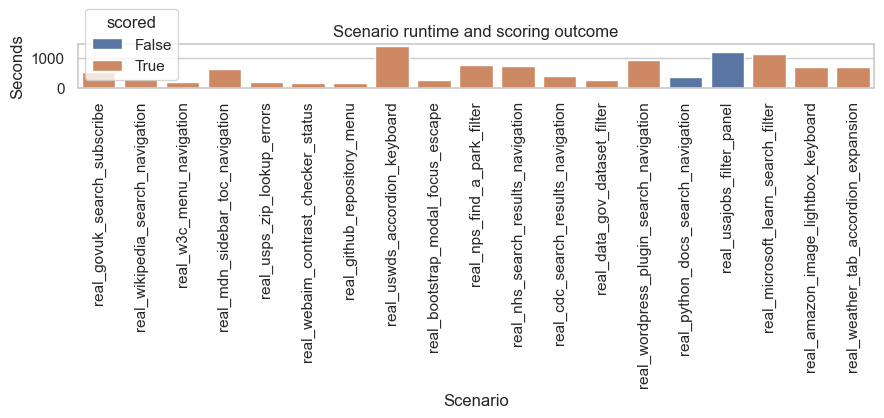

In [7]:
cases = tables["case_records"].copy()
display(cases[["scenario_id", "run_status", "scored", "scenario_attempts", "steps_count", "total_time_s"]])
display(tables["coverage"])
display(tables["performance_cost"])
plot_cases = cases.copy(); plot_cases["total_time_s"] = pd.to_numeric(plot_cases["total_time_s"], errors="coerce")
fig, ax = plt.subplots(figsize=(9, 4.2))
sns.barplot(data=plot_cases, x="scenario_id", y="total_time_s", hue="scored", dodge=False, ax=ax)
ax.set(title="Scenario runtime and scoring outcome", xlabel="Scenario", ylabel="Seconds")
ax.tick_params(axis="x", rotation=90)
plt.tight_layout(); plt.show()

## Interpretation

Flow-A11y produces substantially more criterion-level judgments than a generic browser-agent audit and prevents unresolved evidence references from becoming findings. Its confirmed-fail precision and recall remain insufficient for autonomous conformance assessment; its appropriate current role is to prioritize auditable interaction-dependent findings for expert review.

The evaluation is limited by one execution per website, 17 scored scenarios, 31 oracle failures, model and browser-agent nondeterminism, and the absence of assistive-technology execution.